# Simulating `controlled_swap_trotter_test`

Master-equation simulation of the runtime, with loss, producing the runtime's four plots.

**No phase correction** -- every slope is zero, so the frame drift is assumed absent rather
than tracked. That makes every $W_{sym}$ step identical, which is what lets one step's
superoperator be raised to the $n$th power instead of solving 760 pulses per point.

The sideband coupling is $H = g\,(a\,\sigma^+ e^{i\phi} + a^\dagger \sigma^- e^{-i\phi})$. A
full swap is a $\pi$ rotation of the g1e0 two-level system, i.e. area $\pi/2$, so
$g = \pi / (2\,t_{swap})$ is fixed by the measured swap time, and the short pulse's area is
$\epsilon = g\,t_{short}$. The pulse's **rotation angle is $2\epsilon$**, not $\epsilon$:
a full swap is area $\pi/2$ AND a $\pi$ rotation. Dropping that factor makes
$\theta_{step}$ come out 4x small, so it is anchored below on a solve where one area-$\pi/2$
pulse really does give $P(\text{swapped}) = 1$.

In [61]:
import numpy as np                                     # arrays and math
import qutip as qt                                     # master-equation solver
import matplotlib.pyplot as plt                        # plots

# ---- pulse times, as the config states them (ramp and flat, in seconds) -------------
ramp = 10e-9                                           # every one of these pulses ramps 10 ns
swap_flat = {1: 313.061627e-9, 2: 332.639e-9}          # Q1C1_swap, Q1C2_swap flat lengths
short_flat = {1: 30e-9, 2: 30e-9}                      # Q1C1_short, Q1C2_short flat lengths

# Two different times matter and they are not the same number:
#   effective time = flat + ramp/2  -- the first-order area weighting, what sets the rotation
#   wall time      = flat + ramp    -- how long the pulse actually occupies, what loss sees
swap_eff = {leg: swap_flat[leg] + ramp / 2 for leg in (1, 2)}      # area time of a full swap
short_eff = {leg: short_flat[leg] + ramp / 2 for leg in (1, 2)}    # area time of a short pulse
short_wall = {leg: short_flat[leg] + ramp for leg in (1, 2)}       # real duration, for loss

# ---- the coupling, derived from the swap times -------------------------------------
g = {leg: np.pi / (2 * swap_eff[leg]) for leg in (1, 2)}           # full swap = area pi/2
eps = {leg: g[leg] * short_eff[leg] for leg in (1, 2)}             # short-pulse area, rad
theta = 2 * eps[1] * eps[2]                            # per-step swap angle
n_star = (np.pi / 4) / theta                           # steps to a controlled SWAP

# ---- coherence times (assumptions -- edit these) -----------------------------------
t1_c1 = 900e-6                                          # C1 photon lifetime
t1_c2 = 130e-6                                          # C2 photon lifetime
t2_c1 = 60e-6                                         # C1 total dephasing time
t2_c2 = 60e-6                                         # C2 total dephasing time
t1_qubit = 150e-6                                       # qubit relaxation
t2_qubit = 30e-6                                       # qubit total dephasing time

# ---- the sweep, matching the deployed run ------------------------------------------
steps = list(range(0, 100, 1))                          # trotter_steps: spans n* and 2n*
preps = ["+", "-"]                                     # control_states
read_phase = np.pi / 2                                 # closing pi/2 axis: pi/2 means sigma_y
count_rounds = 3                                       # fock_ladder_top 1 + count_extra 2
iterations = 20000                                     # shots per point
rng = np.random.default_rng(0)                         # fixed seed, reproducible shots

# ---- residual phase-calibration error ----------------------------------------------
# The runtime applies  phase = base + own*N_own + other*N_other  to every pump pulse, and
# base + 4n(m1+m2) to the closing qubit pi/2. Setting these NONZERO is exactly the case where
# the phase calibration is WRONG by that much per sideband: the error then accumulates
# LINEARLY over the train, which is what a miscalibrated slope does.
# Zero means the calibration is assumed perfect. Set any of them by hand to see what a
# residual of that size costs -- these are the same six numbers the runtime takes.
own_slope = {1: 0.0, 2: 0.0}                           # a leg's pulses on its OWN transition
other_slope = {1: 0.0, 2: 0.0}                         # the other leg's pulses on it
qubit_slope = {1: 0.0, 2: 0.0}                         # the qubit frame, on the closing pi/2

## Operators

Space is $C_1 \otimes C_2 \otimes \text{qubit}$, two levels each -- one photon never makes
three. Leg A (q1C1) exchanges a $C_1$ photon for a qubit excitation, leg B (q1C2) a $C_2$ one.

In [62]:
i2 = qt.qeye(2)                                        # 2x2 identity, used to pad tensors
a1 = qt.tensor(qt.destroy(2), i2, i2)                  # C1 lowering operator
a2 = qt.tensor(i2, qt.destroy(2), i2)                  # C2 lowering operator
sm = qt.tensor(i2, i2, qt.destroy(2))                  # qubit lowering operator (|g><e|)
n1_op = a1.dag() * a1                                  # C1 photon number
n2_op = a2.dag() * a2                                  # C2 photon number
pe_op = sm.dag() * sm                                  # qubit excited-state projector
mode = {1: a1, 2: a2}                                  # which cavity each leg couples to

# PURE dephasing rates: the total dephasing time minus the part relaxation already causes.
# The two operators are normalised differently, so the two formulas differ:
#   qubit,  L = sqrt(g/2) sigma_z   -> g/e coherence decays at g, so 1/T2 = 1/(2T1) + g
#   cavity, L = sqrt(g) a^dag a     -> the 0-1 coherence decays at g/2 (the rate goes as
#                                      (delta n)^2, and delta n = 1 here), so
#                                      1/T2 = 1/(2T1) + g/2
# Hence the factor 2 on the cavity lines. Clamped at 0: a T2 longer than 2*T1 is unphysical
# and would ask for a negative rate.
gamma_phi = max(1.0 / t2_qubit - 1.0 / (2 * t1_qubit), 0.0)          # qubit pure dephasing
gamma_c1 = max(2.0 / t2_c1 - 1.0 / t1_c1, 0.0)                       # C1 pure dephasing
gamma_c2 = max(2.0 / t2_c2 - 1.0 / t1_c2, 0.0)                       # C2 pure dephasing
c_ops = [np.sqrt(1.0 / t1_c1) * a1,                    # C1 photon decay
         np.sqrt(1.0 / t1_c2) * a2,                    # C2 photon decay
         np.sqrt(1.0 / t1_qubit) * sm,                 # qubit relaxation
         np.sqrt(gamma_phi / 2) * (2 * pe_op - qt.qeye([2, 2, 2])),   # qubit dephasing
         np.sqrt(gamma_c1) * n1_op,                    # C1 dephasing (photon-number)
         np.sqrt(gamma_c2) * n2_op]                    # C2 dephasing (photon-number)

## Every pulse of the train

Every pulse's phase is the runtime's own expression,
$\phi = \text{base} + m_{own}N_{own} + m_{other}N_{other}$, with the six slopes set to a
residual up to $\pm 0.01$ rad per sideband -- i.e. the case where the phase calibration is
**wrong** by that much. The error then grows **linearly** across the train, which is what a bad
slope does and what a per-pulse scatter does not.

Because the phase now differs from step to step, the train is walked pulse by pulse and the
state snapshotted at each step count, rather than raising one step to the $n$th power.

One step is $W(-\epsilon)W(+\epsilon)$: eight pulses, legs strictly alternating B A B A, signs
$(+,+,-,-,-,-,+,+)$ -- built exactly as the runtime's `wsym_train` does. Four pulses of each
leg per step, which is where the $4n$ in the qubit read axis comes from.

In [63]:
train = []                                             # the LONGEST train, (leg, sign) in order
for _ in range(max(steps)):                            # one group of eight per W_sym step
    for e in (-1, +1):                                 # W(-eps) plays first, then W(+eps)
        train += [(2, -e), (1, -e), (2, +e), (1, +e)]  # B, A, B, A -- strictly alternating

base_phase = {1: np.pi / 2, 2: 0.0}                    # relative_pump_phase_rad on A, B at 0
played = {1: 0, 2: 0}                                  # pulses of each leg played so far
pulse_phase = []                                       # the phase of every pulse, in order
for leg, sign in train:                                # walk the train once
    other = 2 if leg == 1 else 1                       # the other leg
    pulse_phase.append(base_phase[leg]                 # the intended axis
                       + (np.pi if sign < 0 else 0.0)  # a -1 sign is just pi of phase
                       + own_slope[leg] * played[leg]           # drift from its own pulses
                       + other_slope[leg] * played[other])      # drift from the other leg's
    played[leg] += 1                                   # this pulse has now played
pulse_phase = np.array(pulse_phase)                    # array, for the frame plot later

pulse_supers = []                                      # one superoperator per pulse
for (leg, _sign), phase in zip(train, pulse_phase):    # walk the train in time order
    # Scale H so the integrated area is g*t_eff while the solve runs for the full wall time,
    # so the rotation and the loss duration are both right despite the ramp.
    amp = g[leg] * short_eff[leg] / short_wall[leg]    # effective constant amplitude
    h = amp * (mode[leg] * sm.dag() * np.exp(1j * phase)
               + mode[leg].dag() * sm * np.exp(-1j * phase))    # the sideband Hamiltonian
    pulse_supers.append(qt.propagator(h, short_wall[leg], c_ops))     # loss included

step_ns = 8 * short_wall[1] * 1e9                      # one step's duration, ns (legs equal)

## Sweep, closing $\pi/2$, and shots

The closing rotation is a $\pi/2$ about an equatorial axis. With `read_phase = pi/2` that axis
is $\sigma_y$, which maps $|{+}x\rangle \to |e\rangle$ and $|{-}x\rangle \to |g\rangle$ -- so at
$n=0$ prep $+$ reads $P(e)=1$, as the real run does.

After the rotation the qubit and both photon numbers are all diagonal in the same basis, so
the joint measurement is just the diagonal of $\rho$, indexed by $(n_1, n_2, q)$.

In [64]:
p_excited = np.zeros((len(preps), len(steps)))                    # P(qubit = e)
mean_photons = np.zeros((len(preps), len(steps), 2))              # <n1>, <n2>
heralded = np.zeros((len(preps), len(steps), 2, 2))               # [prep, step, qubit, line]
herald_weight = np.zeros((len(preps), len(steps), 2))             # P(qubit outcome)
clicks = np.zeros((len(preps), len(steps), count_rounds, 2))      # P(click) per round
raster = {}                                                       # per-shot records, for plot 3

for pi_, prep in enumerate(preps):                     # the two antipodal preparations
    sgn = 1.0 if prep == "+" else -1.0                 # +X or -X on the qubit
    qubit0 = (qt.basis(2, 0) + sgn * qt.basis(2, 1)).unit()       # (|g> +- |e>)/sqrt2
    rho0 = qt.ket2dm(qt.tensor(qt.basis(2, 1), qt.basis(2, 0), qubit0))   # |1,0> in cavities
    vec = qt.operator_to_vector(rho0)                  # flatten, so the superoperator applies

    snap = {0: vec}                                    # the state after each whole step
    for i, u in enumerate(pulse_supers):               # walk every pulse of the longest train
        vec = u * vec                                  # apply that pulse, with its own error
        if (i + 1) % 8 == 0:                           # a whole W_sym step just finished
            snap[(i + 1) // 8] = vec                   # keep it

    for ni, n in enumerate(steps):                     # every Trotter step count in the sweep
        rho = qt.vector_to_operator(snap[n])           # back to a density matrix
        # The closing pi/2's axis carries the qubit frame the train accumulated: 4n pulses of
        # each leg, so 4n(m1+m2). Rebuilt per n because it grows with the step count.
        phi = read_phase + 4 * n * (qubit_slope[1] + qubit_slope[2])
        axis = np.cos(phi) * qt.sigmax() + np.sin(phi) * qt.sigmay()   # equatorial axis
        u_read = qt.tensor(i2, i2, (-1j * (np.pi / 4) * axis).expm())  # the pi/2 rotation
        rho = u_read * rho * u_read.dag()              # apply the closing pi/2

        probs = np.real(np.diag(rho.full()))           # joint P(n1, n2, q) -- all commute
        probs = np.clip(probs, 0, None)                # kill tiny negative solver residue
        probs = probs / probs.sum()                    # renormalise after the clip

        draw = rng.choice(len(probs), size=iterations, p=probs)   # one outcome per iteration
        idx = np.array([np.unravel_index(d, (2, 2, 2)) for d in draw])   # -> (n1, n2, q)
        qubit, got1, got2 = idx[:, 2], idx[:, 0], idx[:, 1]        # split the three results

        c1 = np.zeros((iterations, count_rounds), int)  # C1 counting record
        c2 = np.zeros((iterations, count_rounds), int)  # C2 counting record
        c1[:, 0] = got1                                 # fock_ladder_top = 1: clicks in round 0
        c2[:, 0] = got2                                 # same for C2

        p_excited[pi_, ni] = qubit.mean()                             # the qubit observable
        mean_photons[pi_, ni] = [c1.sum(1).mean(), c2.sum(1).mean()]  # cavity populations
        clicks[pi_, ni, :, 0] = c1.mean(0)                            # per-round click rate, C1
        clicks[pi_, ni, :, 1] = c2.mean(0)                            # per-round click rate, C2
        for q in (0, 1):                                # herald on each qubit outcome
            m = qubit == q                              # the shots with that outcome
            herald_weight[pi_, ni, q] = m.mean()        # how much weight the branch carries
            if m.any():                                 # guard an empty branch
                heralded[pi_, ni, q] = [c1[m].sum(1).mean(), c2[m].sum(1).mean()]
        raster[(prep, n)] = (c1, c2)                    # keep the records for the shot plot

total_photons = mean_photons.sum(2)                     # the photon budget, <n1> + <n2>
x = np.array(steps, float)                              # the sweep axis

## Heralded cavity population

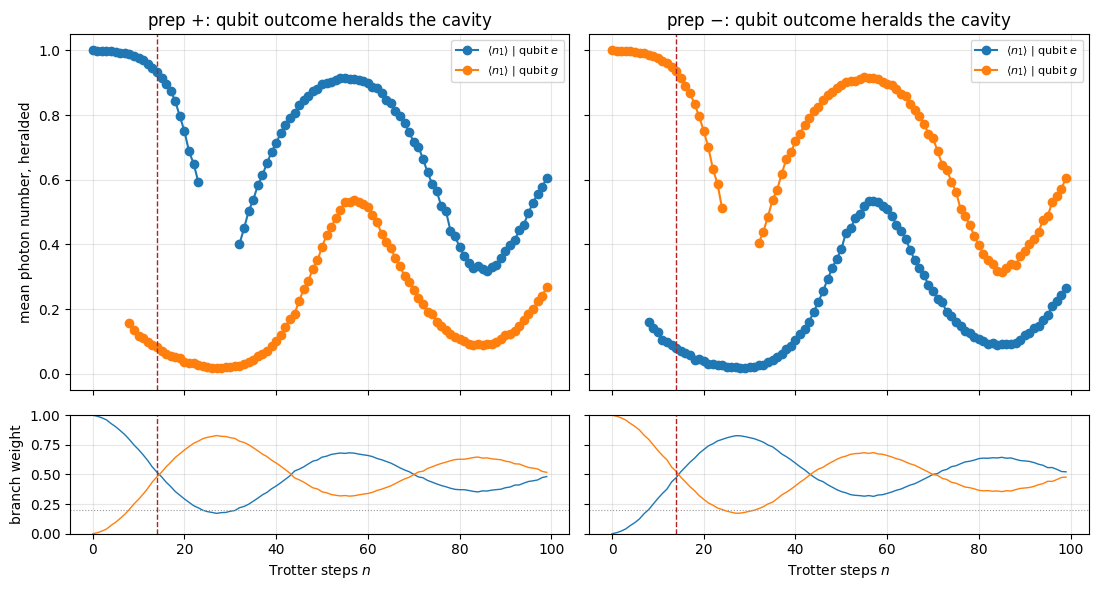

In [65]:
# A heralded value is only a measurement where its branch actually holds shots. P(e) swings
# as cos^2(n theta), so one branch or the other is STARVED for most of the sweep, and there the
# heralded mean is minority-branch contamination rather than signal. Which branch is starved
# alternates at the gate period -- so drawing the line through those points invents an
# oscillation that is not in the data. They are MASKED here (the line breaks) and the branch
# weight is drawn underneath so it is visible why.
floor = 0.20                                                      # need 20% of the shots
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex="col", sharey="row",
                        gridspec_kw={"height_ratios": [3, 1]})
for pi_, prep in enumerate(preps):                                # walk the two preps
    top, bot = axs[0, pi_], axs[1, pi_]
    for q, name, col in ((1, "e", "tab:blue"), (0, "g", "tab:orange")):
        w = herald_weight[pi_, :, q]                              # that branch's weight
        y = np.where(w >= floor, heralded[pi_, :, q, 0], np.nan)   # mask the starved points
        top.plot(x, y, "o-", color=col,
                 label=rf"$\langle n_1\rangle$ | qubit ${name}$")
        bot.plot(x, w, "-", color=col, lw=1)                      # and show the weight
    top.axvline(n_star, color="firebrick", ls="--", lw=1)         # where the CSWAP sits
    top.set_title(f"prep ${prep}$: qubit outcome heralds the cavity")
    top.set_ylim(-0.05, 1.05)
    top.grid(alpha=0.3)
    top.legend(fontsize=8)
    bot.axhline(floor, color="0.6", lw=0.8, ls=":")               # the measurability floor
    bot.axvline(n_star, color="firebrick", ls="--", lw=1)
    bot.set_xlabel("Trotter steps $n$")
    bot.set_ylim(0, 1)
    bot.grid(alpha=0.3)
axs[0, 0].set_ylabel("mean photon number, heralded")
axs[1, 0].set_ylabel("branch weight")
fig.tight_layout()

## The oscillation -- qubit and cavity together

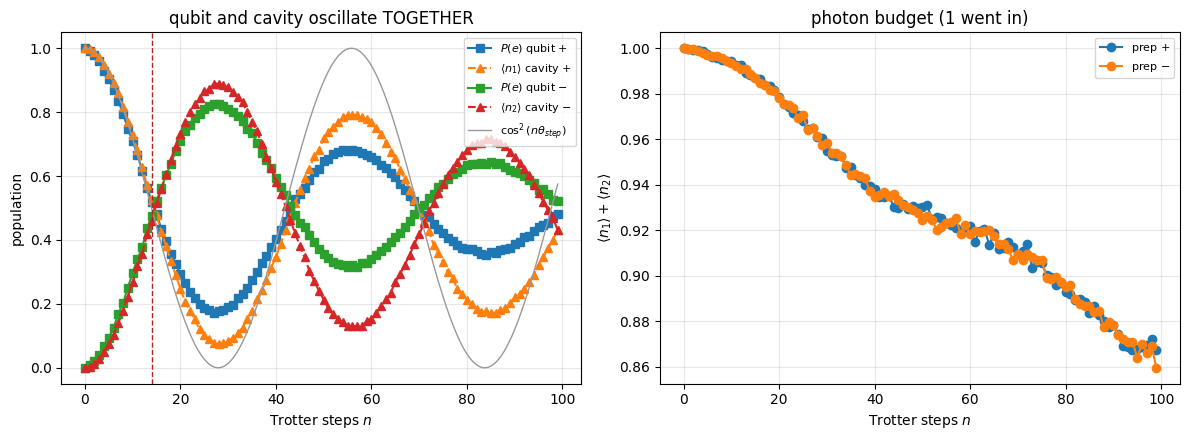

In [66]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))                  # oscillation, then budget
for pi_, prep in enumerate(preps):                                # walk the two preps
    line = 0 if prep == "+" else 1                                # <n1> partners +, <n2> -
    axs[0].plot(x, p_excited[pi_], "s-", label=f"$P(e)$ qubit ${prep}$")
    axs[0].plot(x, mean_photons[pi_, :, line], "^--",             # the cavity partner curve
                label=rf"$\langle n_{line + 1}\rangle$ cavity ${prep}$")
    axs[1].plot(x, total_photons[pi_], "o-", label=f"prep ${prep}$")
fine = np.linspace(0, max(steps), 400)                            # smooth reference curve
axs[0].plot(fine, np.cos(fine * theta) ** 2, color="0.6", lw=1,   # the lossless expectation
            label=r"$\cos^2(n\theta_{step})$")
axs[0].axvline(n_star, color="firebrick", ls="--", lw=1)          # where the CSWAP sits
axs[0].set_xlabel("Trotter steps $n$")
axs[0].set_ylabel("population")
axs[0].set_title("qubit and cavity oscillate TOGETHER")
axs[1].set_xlabel("Trotter steps $n$")
axs[1].set_ylabel(r"$\langle n_1\rangle+\langle n_2\rangle$")
axs[1].set_title("photon budget (1 went in)")
for ax in axs:                                                    # same styling on both
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()

## Counting shots

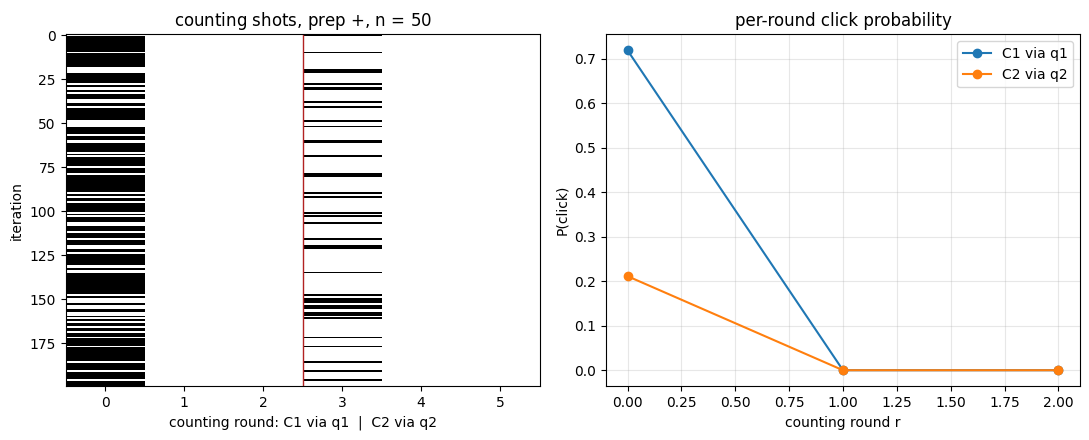

In [67]:
shown = steps[len(steps) // 2]                                    # a step count mid-sweep
c1, c2 = raster[(preps[0], shown)]                                # its records, first prep
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))                  # raster, then click rate
axs[0].imshow(np.concatenate([c1[:200], c2[:200]], axis=1),       # C1 rounds then C2 rounds
              aspect="auto", interpolation="nearest", cmap="Greys")
axs[0].axvline(count_rounds - 0.5, color="firebrick", lw=1)       # the C1 | C2 boundary
axs[0].set_xlabel("counting round: C1 via q1  |  C2 via q2")
axs[0].set_ylabel("iteration")
axs[0].set_title(f"counting shots, prep ${preps[0]}$, n = {shown}")
for line, name in ((0, "C1 via q1"), (1, "C2 via q2")):           # one curve per cavity
    axs[1].plot(range(count_rounds), clicks[0, steps.index(shown), :, line], "o-", label=name)
axs[1].set_xlabel("counting round r")
axs[1].set_ylabel("P(click)")
axs[1].set_title("per-round click probability")
axs[1].grid(alpha=0.3)
axs[1].legend()
fig.tight_layout()

## Pump frame

With no phase correction each leg holds two phases: its base axis, and that axis $+\pi$ for the
sign pattern. Removing the sign pattern leaves two flat lines -- any slope here would be
tracked drift.

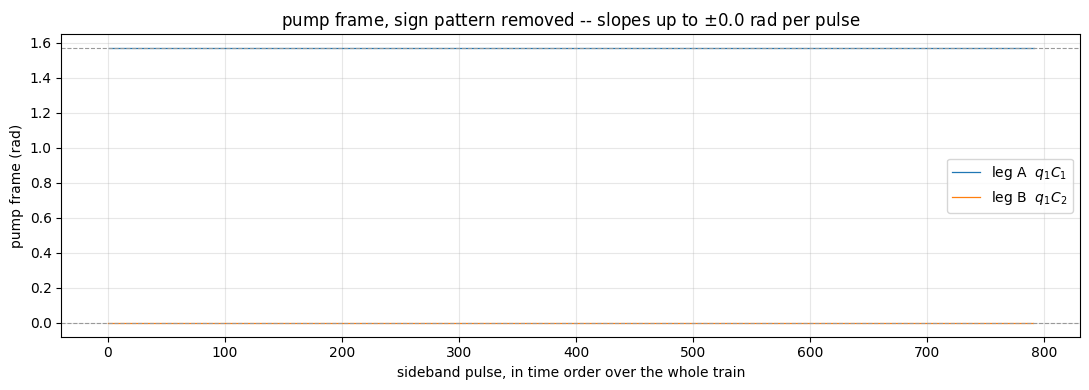

In [68]:
signs = np.array([np.pi if s < 0 else 0.0 for _l, s in train])    # the W_sym sign pattern
frame = pulse_phase - signs                                       # leaves base + the error
fig, ax = plt.subplots(figsize=(11, 4))                           # one panel
for leg, name in ((1, "leg A  $q_1C_1$"), (2, "leg B  $q_1C_2$")):   # a series per leg
    m = np.array([l == leg for l, _s in train])                   # that leg's pulse positions
    ax.plot(np.flatnonzero(m), frame[m], "-", lw=0.9, label=name)  # a LINE: it ramps
    ax.axhline(base_phase[leg], color="0.6", lw=0.8, ls="--")      # the intended axis
ax.set_xlabel("sideband pulse, in time order over the whole train")
ax.set_ylabel("pump frame (rad)")
ax.set_title("pump frame, W_sym sign pattern removed")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

## Random error vs a systematic slope

The $\pm 0.01$ rad per-pulse error above barely moves the curves, which is worth making
explicit rather than leaving as a surprise. A random error adds incoherently -- it grows as
$\sqrt{N}$ and the $W_{sym}$ sign pattern echoes most of it away -- while a systematic slope
accumulates linearly in $N$. At the same per-pulse size the slope is the one that matters.

Run lossless here, so the comparison is the phase error alone.

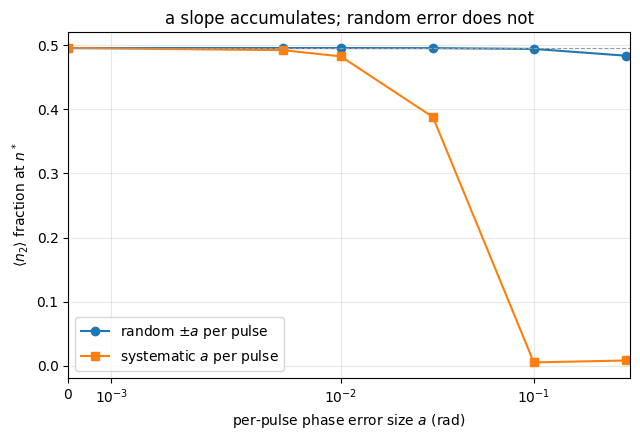

In [69]:
sizes = [0.0, 0.005, 0.01, 0.03, 0.1, 0.3]             # per-pulse error size to scan, rad
at_star = train[:8 * int(round(n_star))]               # just the train up to n*, lossless
psi0 = qt.tensor(qt.basis(2, 1), qt.basis(2, 0),       # |1,0> and the qubit on +X
                 (qt.basis(2, 0) + qt.basis(2, 1)).unit())

def transferred(errors):                               # <n2> fraction after that train
    psi = psi0                                         # start fresh
    for (leg, sign), err in zip(at_star, errors):      # walk the pulses
        phase = base_phase[leg] + (np.pi if sign < 0 else 0.0) + err   # its phase
        amp = g[leg] * short_eff[leg] / short_wall[leg]                # same scaling as above
        h = amp * (mode[leg] * sm.dag() * np.exp(1j * phase)
                   + mode[leg].dag() * sm * np.exp(-1j * phase))
        psi = qt.propagator(h, short_wall[leg]) * psi  # no c_ops: unitary, phase error only
    return qt.expect(n2_op, psi) / (qt.expect(n1_op, psi) + qt.expect(n2_op, psi))

random_curve, slope_curve = [], []                     # one point per error size
for a in sizes:                                        # walk the sizes
    draws = [np.random.default_rng(k).uniform(-a, a, len(at_star)) for k in range(8)]
    random_curve.append(np.mean([transferred(d) for d in draws]))   # average over 8 draws
    played, ramped = {1: 0, 2: 0}, []                  # a slope of the same per-pulse size
    for leg, _sign in at_star:                         # applied to leg B only
        ramped.append(a * played[2] if leg == 2 else 0.0)
        played[leg] += 1
    slope_curve.append(transferred(np.array(ramped)))  # the systematic case

fig, ax = plt.subplots(figsize=(6.5, 4.5))             # one panel
ax.plot(sizes, random_curve, "o-", label="random $\\pm a$ per pulse")
ax.plot(sizes, slope_curve, "s-", label="systematic $a$ per pulse")
ax.axhline(random_curve[0], color="0.6", lw=0.8, ls="--")          # the error-free value
ax.set_xscale("symlog", linthresh=0.005)               # zero plus three decades
ax.set_xlim(left=0)                                    # sizes are non-negative
ax.set_xlabel("per-pulse phase error size $a$ (rad)")
ax.set_ylabel(r"$\langle n_2\rangle$ fraction at $n^*$")
ax.set_title("a slope accumulates; random error does not")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

## Checks

In [70]:
one_step = train[:8]                                   # the first W_sym step
legs = [leg for leg, _s in one_step]                   # its legs, in time order
assert legs.count(1) == 4 and legs.count(2) == 4       # 4 each -- the 4n in the read axis
assert [s for _l, s in one_step] == [1, 1, -1, -1, -1, -1, 1, 1]  # the documented sign pattern
assert legs == [2, 1, 2, 1, 2, 1, 2, 1]                # legs strictly alternate B A B A

# theta_step from a LOSSLESS run of the same step, measured -- no closed form used
unitary = qt.qeye([2, 2, 2])                           # with no collapse ops this stays a UNITARY
for leg, sign in one_step:                             # the same eight pulses, error-free
    phase = base_phase[leg] + (np.pi if sign < 0 else 0.0)
    amp = g[leg] * short_eff[leg] / short_wall[leg]
    h = amp * (mode[leg] * sm.dag() * np.exp(1j * phase)
               + mode[leg].dag() * sm * np.exp(-1j * phase))
    unitary = qt.propagator(h, short_wall[leg]) * unitary   # no c_ops -> plain propagator
probe = 6                                              # a few steps, still in the small-angle
psi = (unitary ** probe) * qt.tensor(qt.basis(2, 1), qt.basis(2, 0),
                                     (qt.basis(2, 0) + qt.basis(2, 1)).unit())
frac = qt.expect(n2_op, psi) / (qt.expect(n1_op, psi) + qt.expect(n2_op, psi))
print(f"theta_step measured {np.arcsin(np.sqrt(frac)) / probe:.6f}   "
      f"2*eps_A*eps_B {theta:.6f}   n* {n_star:.1f}   step {step_ns:.0f} ns")
print(f"gate at n*: {n_star * step_ns / 1000:.1f} us")

theta_step measured 0.055766   2*eps_A*eps_B 0.056291   n* 14.0   step 320 ns
gate at n*: 4.5 us
